In [ ]:
import torch
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


CUDA: True
GPU: NVIDIA RTX A5000


In [ ]:
import os
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


In [ ]:
class NucleiDataset(Dataset):
    def __init__(self, root, size=256):
        self.samples = []
        self.size = size

        for organ in os.listdir(root):
            img_dir = os.path.join(root, organ, "tissue images")
            mask_dir = os.path.join(root, organ, "mask binary without border erode")

            if not os.path.isdir(img_dir):
                continue

            for f in os.listdir(img_dir):
                base = os.path.splitext(f)[0]
                for ext in [".png", ".jpg", ".tif"]:
                    m = os.path.join(mask_dir, base + ext)
                    if os.path.exists(m):
                        self.samples.append((os.path.join(img_dir, f), m))
                        break

        assert len(self.samples) > 0, "No data found!"

        self.img_tf = transforms.Compose([
            transforms.Resize((size, size)),
            transforms.ToTensor(),
            transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
        ])

        self.mask_tf = transforms.Compose([
            transforms.Resize((size, size))
        ])

        print("Total samples:", len(self.samples))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        img_p, mask_p = self.samples[i]
        img = self.img_tf(Image.open(img_p).convert("RGB"))
        mask = np.array(self.mask_tf(Image.open(mask_p).convert("L"))) > 127
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)
        return img, mask


In [ ]:
from segment_anything import sam_model_registry

def load_sam_encoder(device):
    sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth")
    sam.to(device)
    sam.eval()
    for p in sam.parameters():
        p.requires_grad = False
    sam.image_encoder.half()   # 🔥 critical
    return sam.image_encoder


In [ ]:
def pad_to_1024(x):
    _, _, h, w = x.shape
    pad_h = 1024 - h
    pad_w = 1024 - w
    return F.pad(x, (0, pad_w, 0, pad_h), value=0)


In [ ]:
class GLU(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.fc = nn.Conv2d(c, c*2, 1)

    def forward(self, x):
        a, b = self.fc(x).chunk(2, dim=1)
        return a * torch.sigmoid(b)


In [ ]:
class XGatedFusion(nn.Module):
    def __init__(self, local_c, global_c):
        super().__init__()
        self.proj = nn.Conv2d(global_c, local_c, 1)
        self.glu = GLU(local_c)
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(local_c, local_c, 1),
            nn.Sigmoid()
        )

    def forward(self, local, global_):
        global_ = self.proj(global_)
        x = local + global_
        x = self.glu(x)
        x = x * self.se(x)
        return x


In [ ]:
class eUNet3Plus(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = nn.Conv2d(3, 64, 3, padding=1)
        self.enc2 = nn.Conv2d(64, 128, 3, padding=1)
        self.enc3 = nn.Conv2d(128, 256, 3, padding=1)
        self.enc4 = nn.Conv2d(256, 512, 3, padding=1)

        self.pool = nn.MaxPool2d(2)
        self.fuse = XGatedFusion(512, 256)
        self.out = nn.Conv2d(512, 1, 1)

    def forward(self, x, sam_feat):
        x1 = F.relu(self.enc1(x))
        x2 = F.relu(self.enc2(self.pool(x1)))
        x3 = F.relu(self.enc3(self.pool(x2)))
        x4 = F.relu(self.enc4(self.pool(x3)))

        sam_feat = F.interpolate(
         sam_feat.float(),  # 🔥 FIX: cast to FP32
         size=x4.shape[-2:],
         mode="bilinear",
         align_corners=False
         )


        fused = self.fuse(x4, sam_feat)
        out = self.out(fused)

# 🔥 UPSAMPLE BACK TO 256×256
        out = F.interpolate(out, size=x.shape[-2:], mode="bilinear", align_corners=False)

        return out, fused


In [ ]:
def dice_loss(logits, targets):
    p = torch.sigmoid(logits)
    inter = (p * targets).sum()
    return 1 - (2*inter + 1e-6)/(p.sum() + targets.sum() + 1e-6)

bce = nn.BCEWithLogitsLoss()

def total_loss(pred, gt):
    return 0.5*bce(pred, gt) + 0.5*dice_loss(pred, gt)


In [ ]:
ROOT = r"C:\Users\User\Desktop\Btech_asmita\archive"
device = "cuda" if torch.cuda.is_available() else "cpu"

dataset = NucleiDataset(ROOT)
train_ds, val_ds = random_split(dataset, [int(0.8*len(dataset)), len(dataset)//5])

train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=1, num_workers=0)

sam_enc = load_sam_encoder(device)
model = eUNet3Plus().to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
scaler = torch.amp.GradScaler("cuda")


Total samples: 665


In [ ]:
def dice_score(pred, gt, eps=1e-6):
    """
    pred: logits (B,1,H,W)
    gt  : binary mask (B,1,H,W)
    """
    pred = (torch.sigmoid(pred) > 0.5).float()
    gt = gt.float()

    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum()

    return (2.0 * inter + eps) / (union + eps)


def miou_score(pred, gt, eps=1e-6):
    """
    pred: logits (B,1,H,W)
    gt  : binary mask (B,1,H,W)
    """
    pred = (torch.sigmoid(pred) > 0.5).float()
    gt = gt.float()

    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum() - inter

    return (inter + eps) / (union + eps)


In [ ]:
EPOCHS = 50
scaler = torch.amp.GradScaler("cuda")

for epoch in range(EPOCHS):
    # ===================== TRAIN =====================
    model.train()
    train_loss = 0.0

    for imgs, masks in train_loader:
        imgs = imgs.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # -------- SAM feature extraction (SAFE) --------
        with torch.no_grad():
            sam_feats = []
            for i in range(imgs.shape[0]):   # batch-safe
                sam_img = pad_to_1024(imgs[i:i+1]).half()
                sam_feats.append(sam_enc(sam_img))
            sam_feat = torch.cat(sam_feats, dim=0)

        # -------- Forward + Loss --------
        with torch.amp.autocast("cuda"):
            preds, _ = model(imgs, sam_feat)
            loss = total_loss(preds, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()
        torch.cuda.empty_cache()

    train_loss /= len(train_loader)

    # ===================== VALIDATION =====================
    model.eval()
    val_dice = 0.0
    val_miou = 0.0

    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs = imgs.to(device)
            masks = masks.to(device)

            sam_img = pad_to_1024(imgs).half()
            sam_feat = sam_enc(sam_img)

            preds, _ = model(imgs, sam_feat)

            val_dice += dice_score(preds, masks).item()
            val_miou += miou_score(preds, masks).item()

    val_dice /= len(val_loader)
    val_miou /= len(val_loader)

    # ===================== LOG =====================
    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
        f"Loss: {train_loss:.4f} | "
        f"Dice: {val_dice:.4f} | "
        f"mIoU: {val_miou:.4f}"
    )


Epoch [01/50] | Loss: 0.2527 | Dice: 0.6895 | mIoU: 0.5417
Epoch [02/50] | Loss: 0.2494 | Dice: 0.7013 | mIoU: 0.5578
Epoch [03/50] | Loss: 0.2452 | Dice: 0.7040 | mIoU: 0.5598
Epoch [04/50] | Loss: 0.2433 | Dice: 0.7052 | mIoU: 0.5615
Epoch [05/50] | Loss: 0.2443 | Dice: 0.7061 | mIoU: 0.5625
Epoch [06/50] | Loss: 0.2427 | Dice: 0.7041 | mIoU: 0.5596
Epoch [07/50] | Loss: 0.2410 | Dice: 0.7041 | mIoU: 0.5610
Epoch [08/50] | Loss: 0.2359 | Dice: 0.7120 | mIoU: 0.5686
Epoch [09/50] | Loss: 0.2347 | Dice: 0.7140 | mIoU: 0.5721
Epoch [10/50] | Loss: 0.2317 | Dice: 0.7180 | mIoU: 0.5773
Epoch [11/50] | Loss: 0.2325 | Dice: 0.7147 | mIoU: 0.5733
Epoch [12/50] | Loss: 0.2319 | Dice: 0.7164 | mIoU: 0.5755
Epoch [13/50] | Loss: 0.2317 | Dice: 0.7148 | mIoU: 0.5740
Epoch [14/50] | Loss: 0.2272 | Dice: 0.7186 | mIoU: 0.5780
Epoch [15/50] | Loss: 0.2273 | Dice: 0.7078 | mIoU: 0.5664
Epoch [16/50] | Loss: 0.2274 | Dice: 0.7213 | mIoU: 0.5819
Epoch [17/50] | Loss: 0.2237 | Dice: 0.7232 | mIoU: 0.58

In [ ]:
def evaluate_model(
    model,
    sam_enc,
    dataloader,
    device,
    use_sam=True
):
    model.eval()
    dice_total, miou_total = 0.0, 0.0

    with torch.no_grad():
        for imgs, masks in dataloader:
            imgs = imgs.to(device)
            masks = masks.to(device)

            if use_sam:
                sam_img = pad_to_1024(imgs).half()
                sam_feat = sam_enc(sam_img)
            else:
                # 🔥 ZERO global context (no SAM)
                sam_feat = torch.zeros(
                    imgs.size(0), 256,
                    imgs.size(2) // 8,
                    imgs.size(3) // 8,
                    device=device
                )

            preds, _ = model(imgs, sam_feat)

            dice_total += dice_score(preds, masks).item()
            miou_total += miou_score(preds, masks).item()

    dice_avg = dice_total / len(dataloader)
    miou_avg = miou_total / len(dataloader)

    return dice_avg, miou_avg


In [ ]:
print("\n📊 Quantitative Comparison (Validation Set)")

dice_no_sam, miou_no_sam = evaluate_model(
    model=model,
    sam_enc=sam_enc,
    dataloader=val_loader,
    device=device,
    use_sam=False
)

dice_with_sam, miou_with_sam = evaluate_model(
    model=model,
    sam_enc=sam_enc,
    dataloader=val_loader,
    device=device,
    use_sam=True
)

print("\n-------------------------------")
print("Model Variant      Dice    mIoU")
print("-------------------------------")
print(f"w/o SAM         {dice_no_sam:.4f}  {miou_no_sam:.4f}")
print(f"w/  SAM         {dice_with_sam:.4f}  {miou_with_sam:.4f}")
print("-------------------------------")



📊 Quantitative Comparison (Validation Set)

-------------------------------
Model Variant      Dice    mIoU
-------------------------------
w/o SAM         0.7051  0.5659
w/  SAM         0.7408  0.6053
-------------------------------


In [ ]:
def dice_score_bin(pred, gt, eps=1e-6):
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum()
    return ((2 * inter + eps) / (union + eps)).item()


def miou_score_bin(pred, gt, eps=1e-6):
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum() - inter
    return ((inter + eps) / (union + eps)).item()


def denormalize(img):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1,1,3)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1,1,3)
    img = img * std + mean
    return img.clamp(0, 1)


In [ ]:
import os
import matplotlib.pyplot as plt
import torch

def qualitative_human_4x4(
    model,
    sam_enc,
    dataloader,
    device
):
    model.eval()

    dataset = dataloader.dataset
    if hasattr(dataset, "dataset"):   # random_split case
        base_dataset = dataset.dataset
        indices_all = dataset.indices
    else:
        base_dataset = dataset
        indices_all = list(range(len(dataset)))

    # -------- collect ONLY human samples --------
    human_indices = [
        idx for idx in indices_all
        if "human" in base_dataset.samples[idx][0].lower()
    ]

    assert len(human_indices) >= 4, "Not enough human images found!"

    # take first 4 human samples
    selected_indices = human_indices[:4]

    imgs, masks, names = [], [], []

    for idx in selected_indices:
        img, mask = base_dataset[idx]
        imgs.append(img)
        masks.append(mask)
        names.append(os.path.basename(base_dataset.samples[idx][0]))

    imgs = torch.stack(imgs).to(device)
    masks = torch.stack(masks).to(device)

    # ---------- WITH SAM ----------
    with torch.no_grad():
        sam_img = pad_to_1024(imgs).half()
        sam_feat = sam_enc(sam_img)
        preds_sam, _ = model(imgs, sam_feat)

    preds_sam = (torch.sigmoid(preds_sam) > 0.5).float()

    # ---------- WITHOUT SAM ----------
    with torch.no_grad():
        sam_feat_zero = torch.zeros(
            imgs.size(0), 256,
            imgs.size(2)//8, imgs.size(3)//8,
            device=device
        )
        preds_no_sam, _ = model(imgs, sam_feat_zero)

    preds_no_sam = (torch.sigmoid(preds_no_sam) > 0.5).float()

    # ---------- 4 × 4 FIGURE ----------
    fig, axes = plt.subplots(4, 4, figsize=(16, 16))

    for i in range(4):
        img = denormalize(imgs[i].permute(1,2,0).cpu())
        gt = masks[i].squeeze().cpu()
        pr_no = preds_no_sam[i].squeeze().cpu()
        pr_sam = preds_sam[i].squeeze().cpu()

        dice_no = dice_score_bin(pr_no, gt)
        miou_no = miou_score_bin(pr_no, gt)

        dice_sam = dice_score_bin(pr_sam, gt)
        miou_sam = miou_score_bin(pr_sam, gt)

        # Column 1: Image + filename
        axes[i,0].imshow(img)
        axes[i,0].set_title(f"{names[i]}", fontsize=9)
        axes[i,0].axis("off")

        # Column 2: GT
        axes[i,1].imshow(gt, cmap="gray")
        axes[i,1].set_title("Ground Truth", fontsize=10)
        axes[i,1].axis("off")

        # Column 3: w/o SAM
        axes[i,2].imshow(pr_no, cmap="gray")
        axes[i,2].set_title(
            f"w/o SAM\nDice:{dice_no:.3f} | mIoU:{miou_no:.3f}",
            fontsize=9
        )
        axes[i,2].axis("off")

        # Column 4: w/ SAM
        axes[i,3].imshow(pr_sam, cmap="gray")
        axes[i,3].set_title(
            f"w/ SAM\nDice:{dice_sam:.3f} | mIoU:{miou_sam:.3f}",
            fontsize=9
        )
        axes[i,3].axis("off")

    plt.tight_layout()
    plt.show()


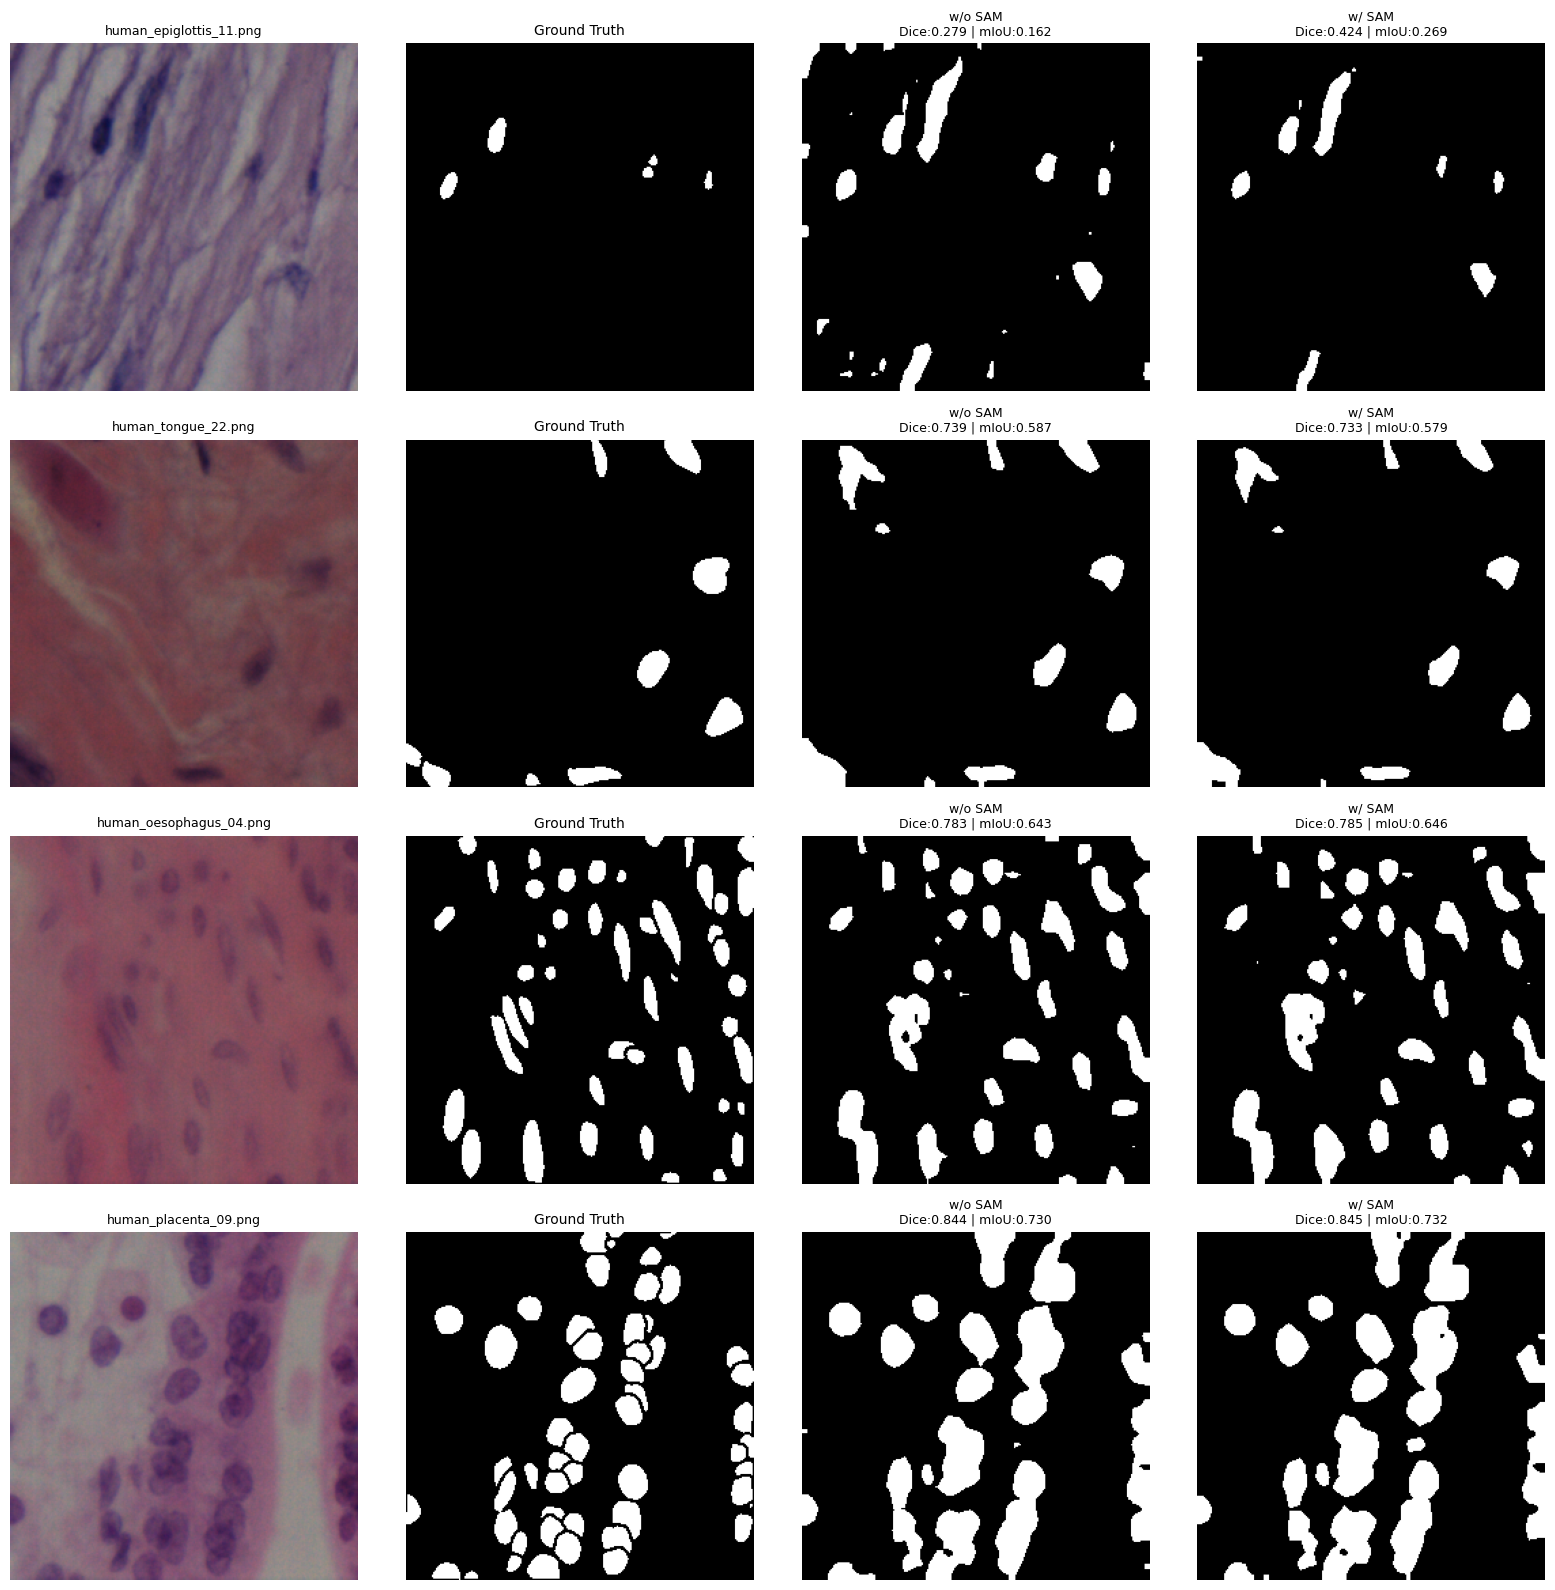

In [ ]:
qualitative_human_4x4(
    model=model,
    sam_enc=sam_enc,
    dataloader=val_loader,
    device=device
)


In [ ]:
def dice_score_bin(pred, gt, eps=1e-6):
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum()
    return ((2 * inter + eps) / (union + eps)).item()


def miou_score_bin(pred, gt, eps=1e-6):
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum() - inter
    return ((inter + eps) / (union + eps)).item()


In [ ]:
def denormalize(img):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1,1,3)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1,1,3)
    img = img * std + mean
    return img.clamp(0, 1)


In [ ]:
import os
import matplotlib.pyplot as plt

def qualitative_paper_style_show_filename(
    model,
    sam_enc,
    dataloader,
    device,
    num_samples=3
):
    model.eval()

    # ---- get one batch ----
    imgs, masks = next(iter(dataloader))
    batch_size = imgs.size(0)
    num_samples = min(num_samples, batch_size)

    imgs = imgs[:num_samples].to(device)
    masks = masks[:num_samples].to(device)

    # ---- get image file names safely ----
    dataset = dataloader.dataset
    if hasattr(dataset, "dataset"):   # random_split case
        base_dataset = dataset.dataset
        indices = dataset.indices[:num_samples]
    else:
        base_dataset = dataset
        indices = list(range(num_samples))

    image_names = [
        os.path.basename(base_dataset.samples[idx][0])
        for idx in indices
    ]

    # ---------- WITH SAM ----------
    with torch.no_grad():
        sam_img = pad_to_1024(imgs).half()
        sam_feat = sam_enc(sam_img)
        preds_sam, _ = model(imgs, sam_feat)

    preds_sam = (torch.sigmoid(preds_sam) > 0.5).float()

    # ---------- WITHOUT SAM ----------
    with torch.no_grad():
        sam_feat_zero = torch.zeros(
            imgs.size(0), 256,
            imgs.size(2)//8, imgs.size(3)//8,
            device=device
        )
        preds_no_sam, _ = model(imgs, sam_feat_zero)

    preds_no_sam = (torch.sigmoid(preds_no_sam) > 0.5).float()

    # ---------- FIGURE ----------
    fig, axes = plt.subplots(
        num_samples, 4,
        figsize=(16, 4 * num_samples)
    )

    if num_samples == 1:
        axes = axes[None, :]

    for i in range(num_samples):
        img = denormalize(imgs[i].permute(1,2,0).cpu())
        gt = masks[i].squeeze().cpu()
        pr_no = preds_no_sam[i].squeeze().cpu()
        pr_sam = preds_sam[i].squeeze().cpu()

        dice_no = dice_score_bin(pr_no, gt)
        miou_no = miou_score_bin(pr_no, gt)

        dice_sam = dice_score_bin(pr_sam, gt)
        miou_sam = miou_score_bin(pr_sam, gt)

        # Original image (with FILE NAME)
        axes[i,0].imshow(img)
        axes[i,0].set_title(f"Image: {image_names[i]}", fontsize=9)
        axes[i,0].axis("off")

        # Ground truth
        axes[i,1].imshow(gt, cmap="gray")
        axes[i,1].set_title("Ground Truth", fontsize=10)
        axes[i,1].axis("off")

        # w/o SAM
        axes[i,2].imshow(pr_no, cmap="gray")
        axes[i,2].set_title(
            f"w/o SAM\nDice: {dice_no:.3f} | mIoU: {miou_no:.3f}",
            fontsize=9
        )
        axes[i,2].axis("off")

        # w/ SAM
        axes[i,3].imshow(pr_sam, cmap="gray")
        axes[i,3].set_title(
            f"w/ SAM\nDice: {dice_sam:.3f} | mIoU: {miou_sam:.3f}",
            fontsize=9
        )
        axes[i,3].axis("off")

    plt.tight_layout()
    plt.show()


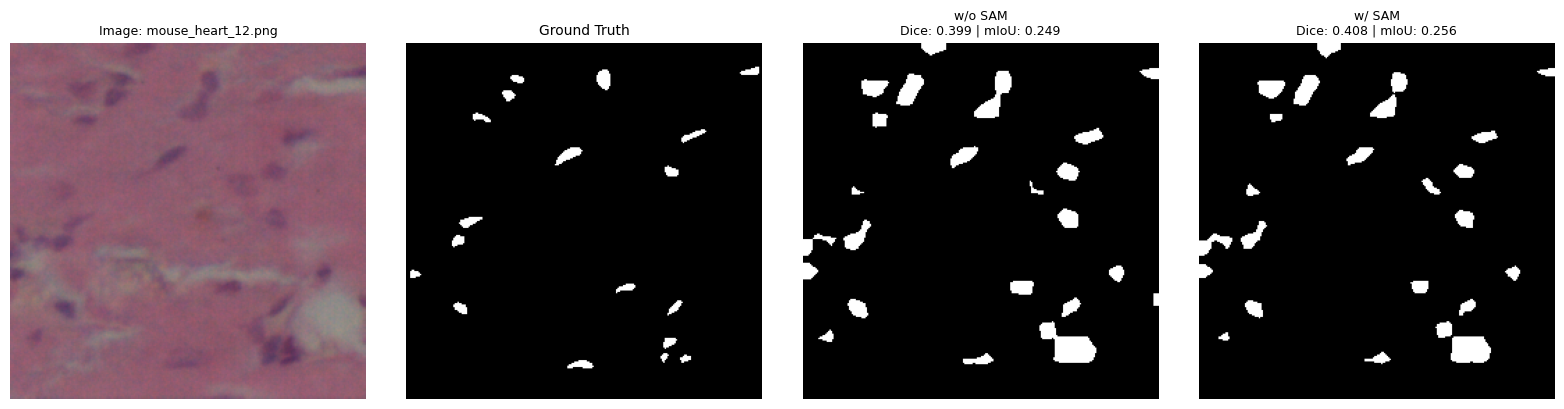

In [ ]:
qualitative_paper_style_show_filename(
    model=model,
    sam_enc=sam_enc,
    dataloader=val_loader,
    device=device,
    num_samples=3
)
